<a href="https://colab.research.google.com/github/kurupathianuradha4-lang/CS5720-Home-Assignment-3/blob/main/Homework_assigment3_anu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Convolution from Scratch

In [1]:
import numpy as np

# (a) Store input and filter as NumPy arrays
image = np.array([
    [1, 1, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 1, 1],
    [0, 0, 1, 1, 0],
    [0, 1, 1, 0, 0],
])
kernel = np.array([
    [1, 0, 1],
    [0, 1, 0],
    [1, 0, 1],
])

def conv2d(img, ker, stride=1, padding=0):
    """Slide `ker` over `img` and take the dot product at every valid location."""
    if padding > 0:
        img = np.pad(img, padding, mode="constant", constant_values=0)
    n_h, n_w = img.shape
    f_h, f_w = ker.shape
    out_h = (n_h - f_h) // stride + 1      # floor((N - F + 2P) / S) + 1
    out_w = (n_w - f_w) // stride + 1
    out = np.zeros((out_h, out_w), dtype=img.dtype)

    # (b) Slide the filter over the input
    for i in range(out_h):
        for j in range(out_w):
            r, c = i * stride, j * stride
            patch = img[r:r + f_h, c:c + f_w]   # current receptive field
            # (c) Dot product: element-wise multiply, then sum
            out[i, j] = np.sum(patch * ker)
    return out

result = conv2d(image, kernel, stride=1, padding=0)

# (d) Print the complete output feature map
print("Output feature map:")
print(result)

# (e) Print the output shape
print("Output shape:", result.shape)

# Stride = 2, for part (f)
print("\nStride 2 output:")
print(conv2d(image, kernel, stride=2))

Output feature map:
[[4 3 4]
 [2 4 3]
 [2 3 4]]
Output shape: (3, 3)

Stride 2 output:
[[4 4]
 [2 4]]


Transfer Learning, Freeze vs. Fine-Tune

100%|██████████| 170M/170M [23:20<00:00, 122kB/s]


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 170MB/s]



=== Experiment A: Frozen Feature Extractor === trainable parameters: 1,026
Epoch 1/5  loss = 0.6254
Epoch 2/5  loss = 0.4400
Epoch 3/5  loss = 0.3764
Epoch 4/5  loss = 0.3387
Epoch 5/5  loss = 0.3230
Time: 12.7s | Accuracy: 86.50%

=== Experiment B: Fine-Tuned Network === trainable parameters: 8,394,754
Epoch 1/5  loss = 0.2812
Epoch 2/5  loss = 0.0723
Epoch 3/5  loss = 0.0215
Epoch 4/5  loss = 0.0105
Epoch 5/5  loss = 0.0085
Time: 10.9s | Accuracy: 94.10%


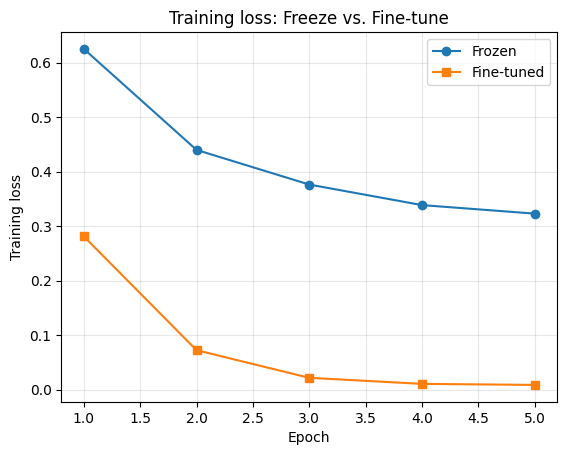


| Method | Trainable Parameters | Training Time | Accuracy |
| --- | --- | --- | --- |
| Frozen Feature Extractor | 1,026 | 12.7 s | 86.50% |
| Fine-Tuned Network | 8,394,754 | 10.9 s | 94.10% |


In [1]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import transforms, models
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

# ---------------- Config ----------------
SEED = 42
EPOCHS = 5                  # same number of epochs for both experiments
BATCH_SIZE = 64
LR = 1e-3
CLASSES = (0, 8)            # CIFAR-10: 0 = airplane, 8 = ship
TRAIN_PER_CLASS = 1000
TEST_PER_CLASS = 500
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)

# ---------------- Data ----------------
tfm = transforms.Compose([
    transforms.Resize(112),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),  # ImageNet stats
])

def make_subset(train, per_class):
    """Keep only the chosen classes, `per_class` images each, relabelled 0/1."""
    ds = torchvision.datasets.CIFAR10("./data", train=train, download=True, transform=tfm)
    idx, counts = [], {c: 0 for c in CLASSES}
    for i, y in enumerate(ds.targets):
        if y in counts and counts[y] < per_class:
            idx.append(i)
            counts[y] += 1
    ds.targets = [CLASSES.index(y) if y in CLASSES else y for y in ds.targets]
    return Subset(ds, idx)

train_set = make_subset(True, TRAIN_PER_CLASS)
test_set = make_subset(False, TEST_PER_CLASS)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE)

# ---------------- Helpers ----------------
def build_model(fine_tune):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    for p in model.parameters():            # freeze the whole pretrained backbone
        p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))  # new classifier (trainable)
    if fine_tune:                           # Experiment B: unfreeze last conv block
        for p in model.layer4.parameters():
            p.requires_grad = True
    return model.to(DEVICE)

def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def evaluate(model):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            correct += (model(x).argmax(1) == y).sum().item()
            total += y.size(0)
    return 100.0 * correct / total

def run_experiment(name, fine_tune):
    torch.manual_seed(SEED)
    model = build_model(fine_tune)
    trainable = count_trainable(model)                      # (a) trainable parameters
    print(f"\n=== {name} === trainable parameters: {trainable:,}")
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR)

    losses = []
    start = time.time()
    for epoch in range(EPOCHS):                             # (b) same epochs
        model.train()
        running = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            running += loss.item() * x.size(0)
        losses.append(running / len(train_set))
        print(f"Epoch {epoch+1}/{EPOCHS}  loss = {losses[-1]:.4f}")
    train_time = time.time() - start                        # (c) training time
    acc = evaluate(model)                                   # (d) test accuracy
    print(f"Time: {train_time:.1f}s | Accuracy: {acc:.2f}%")
    return dict(params=trainable, time=train_time, acc=acc, losses=losses)

# ---------------- Run both experiments ----------------
a = run_experiment("Experiment A: Frozen Feature Extractor", fine_tune=False)
b = run_experiment("Experiment B: Fine-Tuned Network", fine_tune=True)

# (e) Plot training loss
plt.plot(range(1, EPOCHS + 1), a["losses"], marker="o", label="Frozen")
plt.plot(range(1, EPOCHS + 1), b["losses"], marker="s", label="Fine-tuned")
plt.xlabel("Epoch"); plt.ylabel("Training loss"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Training loss: Freeze vs. Fine-tune")
plt.savefig("training_loss.png", dpi=150)
plt.show()

# (f) Comparison table
print("\n| Method | Trainable Parameters | Training Time | Accuracy |")
print("| --- | --- | --- | --- |")
print(f"| Frozen Feature Extractor | {a['params']:,} | {a['time']:.1f} s | {a['acc']:.2f}% |")
print(f"| Fine-Tuned Network | {b['params']:,} | {b['time']:.1f} s | {b['acc']:.2f}% |")